# 03 · How our data works: from a satellite picture to numbers

This notebook answers four questions with pictures of our own data; section 6 sums up the answers.

1. What is a satellite image, and what is a **band**? (sections 1–2)
2. What do we actually download: the whole image, or only numbers? (section 3)
3. How do **Presto**, a **CNN / MOSAIKS** and **AlphaEarth** read the same data differently? (section 4)
4. How does every field end up as one row with one yield? (section 5)

**The short answer.** We download real pixels, but only a small window around each field: a *data cube* of
months × 10 bands × 64 × 64 pixels. Each model family then reads a different part of that cube.

It needs the 48 pilot chips (`python scripts/get_data.py`, or the commands in `02_pilot48.ipynb`). Nothing is
trained.

In [1]:
import json
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from matplotlib.patches import Rectangle
from rasterio.transform import Affine
from rasterio.warp import transform_geom
from shapely.geometry import shape

from cropyield import ROOT
from cropyield.data.cohorts import load_cohort
from cropyield.longpath import filesystem_path, path_exists
from cropyield.satellite.chips import read_chip
from cropyield.satellite.monthly import month_range, monthly_series

plt.rcParams.update({"figure.dpi": 95, "axes.titlesize": 10, "axes.spines.top": False, "axes.spines.right": False})
IMAGERY = ROOT / "data" / "imagery" / "sentinel2"
BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
BAND_NAMES = {"B02": "blue", "B03": "green", "B04": "red", "B05": "red edge 1", "B06": "red edge 2",
              "B07": "red edge 3", "B08": "near-infrared", "B8A": "narrow NIR", "B11": "shortwave IR 1",
              "B12": "shortwave IR 2"}
CENTRE_NM = {"B02": 490, "B03": 560, "B04": 665, "B05": 704, "B06": 740, "B07": 783, "B08": 842, "B8A": 865,
             "B11": 1610, "B12": 2190}
WIDTH_NM = {"B02": 66, "B03": 36, "B04": 31, "B05": 15, "B06": 15, "B07": 20, "B08": 106, "B8A": 21, "B11": 91,
            "B12": 175}

windows = pd.read_csv(ROOT / "configs" / "sentinel2_windows_pilot48.csv", dtype=str)
labels = pd.concat([load_cohort(c) for c in windows["cohort"].unique()]).set_index("obs_id")
pilot = labels.loc[[f"{d}:{s}" for d, s in zip(windows["dataset"], windows["source_id"])]]


def load_field(obs_id):
    """Chip, record.json and monthly table of one pilot field (the chip downloaded for its season window)."""
    row = pilot.loc[obs_id]
    safe_id = re.sub(r"[^A-Za-z0-9_-]", "_", row["source_id"])[:64]
    for folder in sorted(IMAGERY.glob(f"run-*/records/{row['dataset']}__{safe_id}__*"), reverse=True):
        if path_exists(folder / "record.json"):
            record = json.loads(Path(filesystem_path(folder / "record.json")).read_text())
            if (record["record"]["start_date"], record["record"]["end_date"]) == (row["season_start"], row["season_end"]):
                chip = read_chip(folder)
                window = (date.fromisoformat(row["season_start"]), date.fromisoformat(row["season_end"]))
                return chip, record, monthly_series(chip, *window)
    raise FileNotFoundError(f"no chip for {obs_id}; run python scripts/get_data.py first")


def rgb(scene, chip, bands=("B04", "B03", "B02"), top=0.3):
    """Three bands as a colour picture; pixels the cloud mask removed show white."""
    image = np.stack([scene.reflectance[chip.bands.index(b)] for b in bands], axis=-1) / top
    return np.nan_to_num(np.clip(image, 0, 1), nan=1.0)


def outline(chip, record):
    """Field polygon rings (or the point) in pixel coordinates of the chip."""
    projected = shape(transform_geom("EPSG:4326", chip.crs, record["record"]["geometry"]))
    to_pixel = ~Affine(*chip.transform)
    if projected.geom_type == "Point":
        column, row_ = to_pixel * (projected.x, projected.y)
        return [(np.array([column - 0.5]), np.array([row_ - 0.5]))]
    parts = projected.geoms if projected.geom_type == "MultiPolygon" else [projected]
    return [tuple(np.array(v) - 0.5 for v in zip(*(to_pixel * xy for xy in p.exterior.coords))) for p in parts]


def ndvi_of(scene, chip):
    nir, red = scene.reflectance[chip.bands.index("B08")], scene.reflectance[chip.bands.index("B04")]
    return (nir - red) / (nir + red)


POLY_ID = "malawi_2023:1d60c29e-ee3a-4639-9e07-0239523dfc62"    # a walked field polygon, 0.83 ha
POINT_ID = "one_acre_fund_full:ee151220"                          # a Kenya GPS point, 2019 long rains
chip, record, series = load_field(POLY_ID)
field = chip.aoi_interior
greenest = max(chip.scenes, key=lambda s: np.nanmedian(ndvi_of(s, chip)[field]))
driest = min(chip.scenes, key=lambda s: np.nanmedian(ndvi_of(s, chip)[field]))
print(f"field {POLY_ID.split(':')[1][:8]} | yield {pilot.at[POLY_ID, 'yield_kg_ha']:,.0f} kg/ha | "
      f"{len(chip.scenes)} accepted scenes | greenest {greenest.date} | driest {driest.date}")

field 1d60c29e | yield 3,310 kg/ha | 5 accepted scenes | greenest 2023-03-07 | driest 2022-12-17


## 1. A satellite image is a stack of brightness maps

A normal photo has 3 layers: red, green and blue. A Sentinel-2 image has 13; we keep **10**. Each layer, a
**band**, is a grey-scale map: how much light of *one colour* comes back from each 10 m × 10 m square of ground
(six bands are measured at 20 m and put on the same 10 m grid, so they look softer). Below are the 10 bands of
one scene over our field, in order of wavelength. Bright = much light comes back.

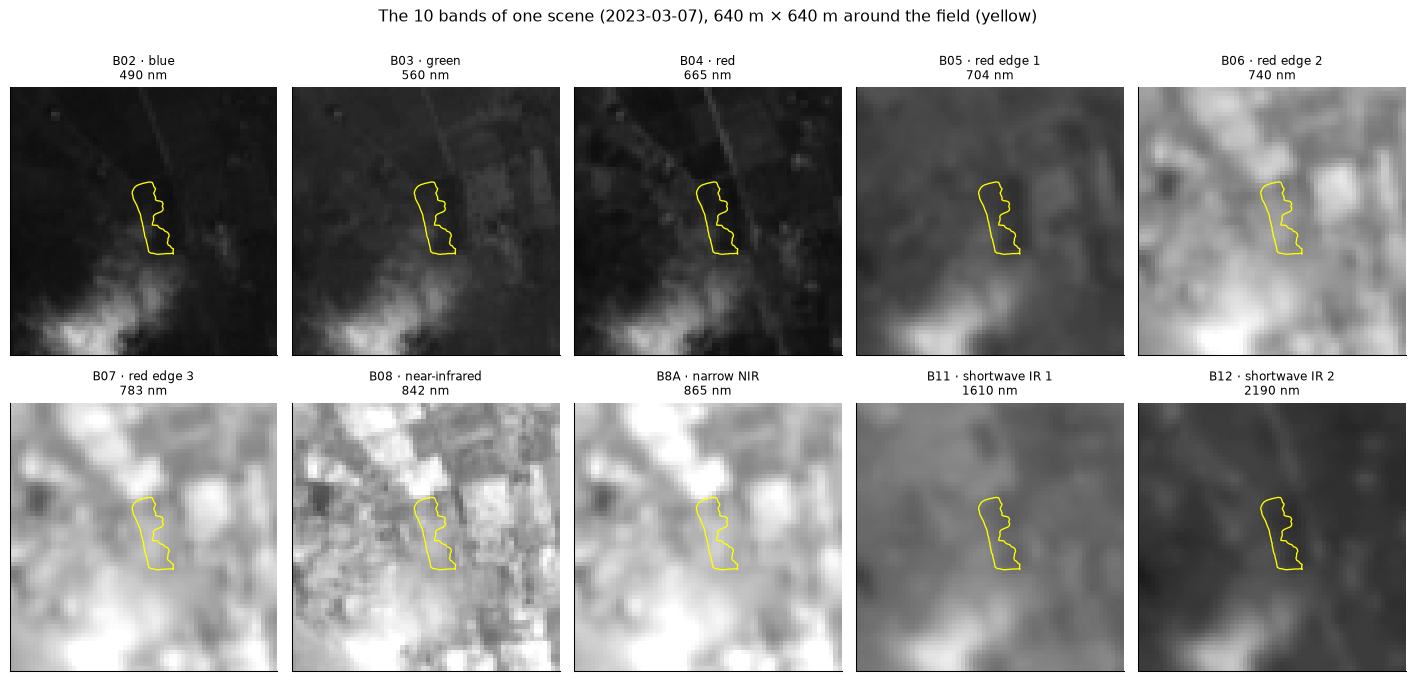

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7.4))
rings = outline(chip, record)
for ax, band in zip(axes.flat, BANDS):
    ax.imshow(greenest.reflectance[chip.bands.index(band)], cmap="gray", vmin=0, vmax=0.45)
    for columns, rows_ in rings:
        ax.plot(columns, rows_, color="yellow", lw=1)
    ax.set_title(f"{band} · {BAND_NAMES[band]}\n{CENTRE_NM[band]} nm", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"The 10 bands of one scene ({greenest.date}), 640 m × 640 m around the field (yellow)", y=1.0)
plt.tight_layout()
plt.show()

The field is **dark** in the visible bands (blue, green, red) and **bright** in near-infrared. That is the plant
signal: leaves absorb red light for photosynthesis and reflect near-infrared light.

A colour photo is only three of these layers put on top of each other, one per screen colour:

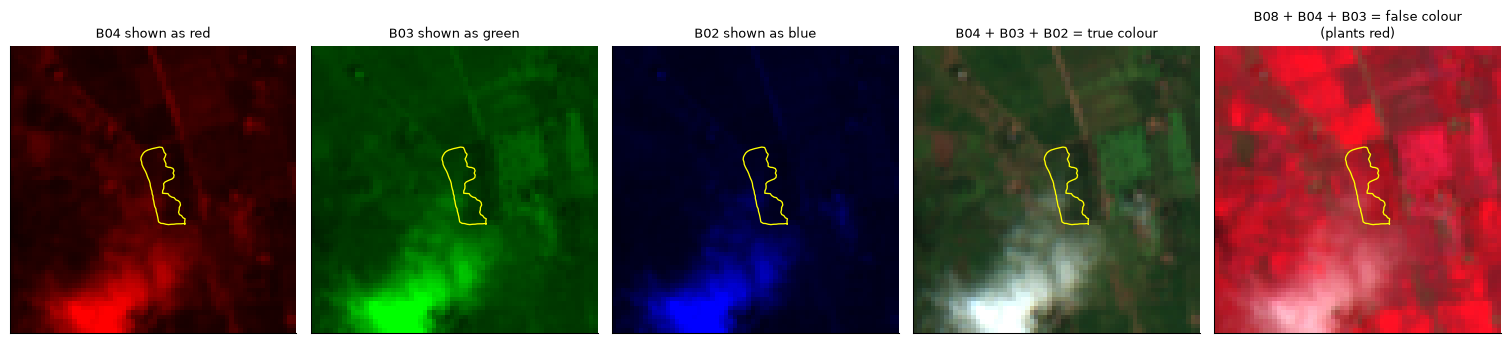

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (band, tint) in zip(axes[:3], [("B04", 0), ("B03", 1), ("B02", 2)]):
    layer = np.zeros(chip.aoi.shape + (3,))
    layer[..., tint] = np.nan_to_num(np.clip(greenest.reflectance[chip.bands.index(band)] / 0.3, 0, 1))
    ax.imshow(layer)
    ax.set_title(f"{band} shown as {['red', 'green', 'blue'][tint]}")
axes[3].imshow(rgb(greenest, chip))
axes[3].set_title("B04 + B03 + B02 = true colour")
axes[4].imshow(rgb(greenest, chip, ("B08", "B04", "B03"), top=0.45))
axes[4].set_title("B08 + B04 + B03 = false colour\n(plants red)")
for ax in axes:
    for columns, rows_ in rings:
        ax.plot(columns, rows_, color="yellow", lw=1)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## 2. What a band measures: one colour of light

Each band is a narrow slice of the light spectrum (the shaded bars). The curves are **measured from our chip**:
the median of all pixels that ESA's scene classification calls *vegetation* in the green month, and *bare soil*
in the dry month. The two surfaces look almost alike in the visible part and very different after 700 nm.
That difference is what vegetation indices and Presto pick up.

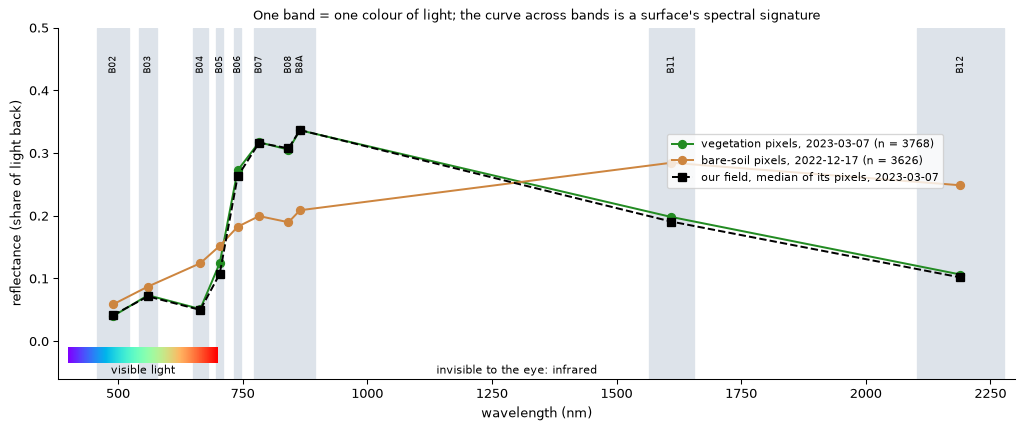

In [4]:
def surface_curve(scene, scl_class):
    pixels = scene.scl == scl_class
    return np.array([np.nanmedian(scene.reflectance[chip.bands.index(b)][pixels]) for b in BANDS]), int(pixels.sum())


green_curve, n_green = surface_curve(greenest, 4)
soil_curve, n_soil = surface_curve(driest, 5)
field_green = series.values[series.months.index(greenest.date.strftime("%Y-%m"))]
centres = np.array([CENTRE_NM[b] for b in BANDS])

fig, ax = plt.subplots(figsize=(13, 4.8))
spectrum = np.linspace(400, 700, 200)
ax.imshow(spectrum[None], extent=(400, 700, -0.035, -0.01), aspect="auto", cmap="rainbow", zorder=3)
ax.text(550, -0.052, "visible light", ha="center", fontsize=8)
ax.text(1300, -0.052, "invisible to the eye: infrared", ha="center", fontsize=8)
for band in BANDS:
    ax.axvspan(CENTRE_NM[band] - WIDTH_NM[band] / 2, CENTRE_NM[band] + WIDTH_NM[band] / 2, color="#dde3ea", zorder=0)
    ax.text(CENTRE_NM[band], 0.43, band, ha="center", fontsize=7, rotation=90)
ax.plot(centres, green_curve, "o-", color="forestgreen", label=f"vegetation pixels, {greenest.date} (n = {n_green})")
ax.plot(centres, soil_curve, "o-", color="peru", label=f"bare-soil pixels, {driest.date} (n = {n_soil})")
ax.plot(centres, field_green, "s--", color="black", label=f"our field, median of its pixels, {greenest.date}")
ax.set(xlim=(380, 2300), ylim=(-0.06, 0.5), xlabel="wavelength (nm)", ylabel="reflectance (share of light back)",
       title="One band = one colour of light; the curve across bands is a surface's spectral signature")
ax.legend(loc="center right", bbox_to_anchor=(0.93, 0.62), fontsize=8)
plt.show()

## 3. One field over one season is a data cube

The downloader keeps at most one clear scene per month of the season window. Put the months on top of each other
and one field becomes a **cube**: months × bands × rows × columns. These are the raw pixels we have on disk
(`data/imagery/sentinel2/.../reflectance.tif`). Grey planes are months without a clear scene.

data cube of this field: (9, 10, 64, 64) = (months, bands, rows, columns) | 55% of the values are present


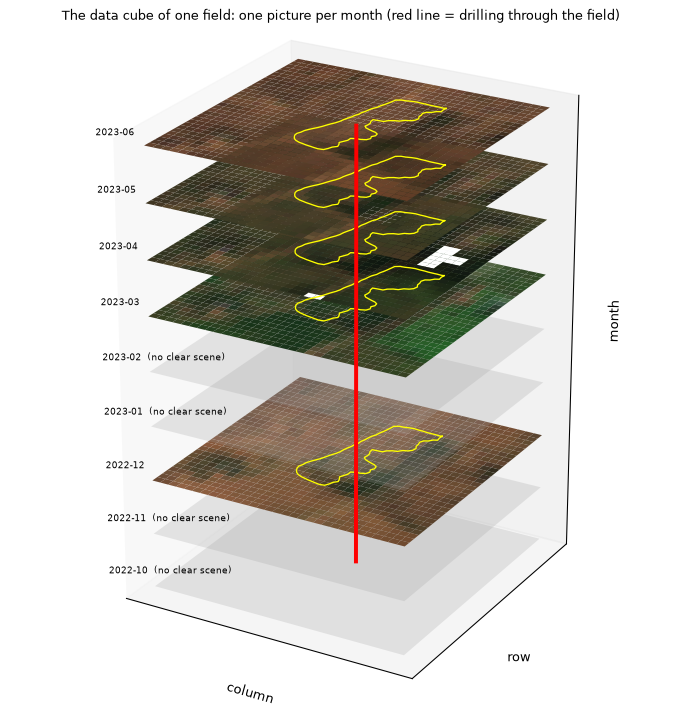

In [5]:
months = month_range(date.fromisoformat(pilot.at[POLY_ID, "season_start"]),
                     date.fromisoformat(pilot.at[POLY_ID, "season_end"]))
by_month = {s.date.strftime("%Y-%m"): s for s in chip.scenes}
cube = np.full((len(months), len(BANDS), *chip.aoi.shape), np.nan, dtype="float32")
for k, month in enumerate(months):
    if month in by_month:
        cube[k] = by_month[month].reflectance
print("data cube of this field:", cube.shape, "= (months, bands, rows, columns)",
      f"| {np.isfinite(cube).mean():.0%} of the values are present")

rows_in, cols_in = np.where(chip.aoi)
centre_row, centre_col = int(rows_in.mean()), int(cols_in.mean())
crop = (slice(centre_row - 16, centre_row + 16), slice(centre_col - 16, centre_col + 16))
Y, X = np.mgrid[0:32, 0:32]
fig = plt.figure(figsize=(9, 10))
ax = fig.add_subplot(projection="3d", computed_zorder=False)   # draw in call order: bottom month first
for k, month in enumerate(months):
    if month in by_month:
        ax.plot_surface(X, Y, np.full(X.shape, k), facecolors=rgb(by_month[month], chip)[crop], rstride=1, cstride=1,
                        shade=False, linewidth=0)
        for columns, rows_ in rings:
            ax.plot(columns - crop[1].start, rows_ - crop[0].start, k, color="yellow", lw=1)
    else:
        ax.plot_surface(X, Y, np.full(X.shape, k), color="lightgrey", alpha=0.25, linewidth=0, rstride=31, cstride=31)
    ax.text(-6, 0, k, month + ("" if month in by_month else "  (no clear scene)"), fontsize=7)
ax.plot([centre_col - crop[1].start] * 2, [centre_row - crop[0].start] * 2, [0, len(months) - 1], color="red", lw=3)
ax.set(xlabel="column", ylabel="row", zlabel="month", zticks=[], xticks=[], yticks=[])
ax.set_box_aspect((1, 1, 1.5))
ax.view_init(elev=24, azim=-60)
ax.set_title("The data cube of one field: one picture per month (red line = drilling through the field)")
plt.show()

## 4. Three ways to read the same cube

This is the key idea of the project. The cube is the same for everyone; each model family reads a different part.

| | What it reads | Shape for this field | Who uses it |
|---|---|---|---|
| **A. Drill down** | the field's pixels, through time; space is averaged away | months × bands | vegetation indices, GRU, **Presto** |
| **B. Cut a slice** | one month, all pixels; space is kept | bands × rows × columns | **CNN**, **MOSAIKS** |
| **C. Pre-digested** | someone else's model already read space, time and many sensors | 64 numbers per pixel per year | **AlphaEarth** |

### A. Drill down: the field's time series (Presto, indices, GRU)

For each month, take the pixels inside the field and keep the median of each band. The picture disappears;
one small table remains. **This is exactly what Presto reads**: Presto is a *pixel time-series* model. It never
sees neighbours, shapes or textures; it sees how the 10 band values of one place change over the months.

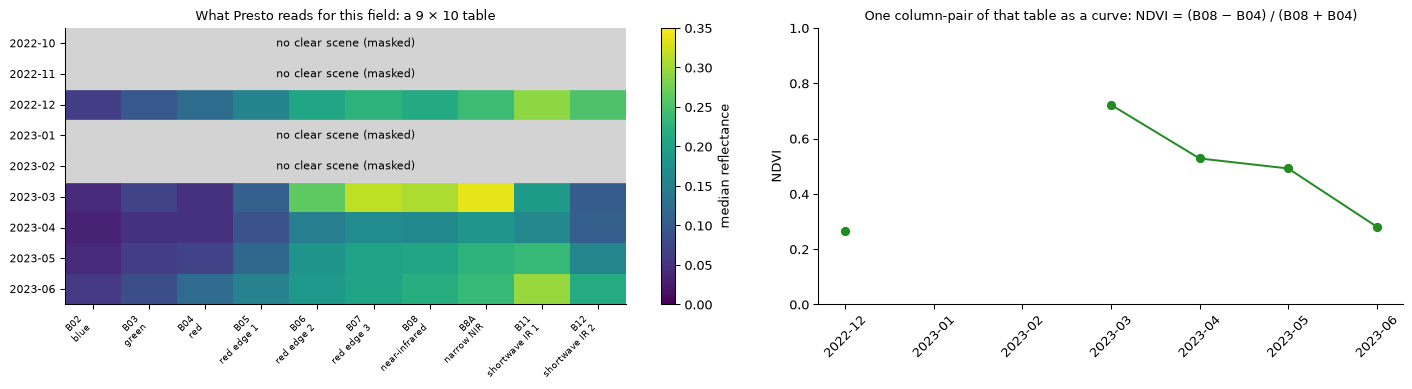

In [6]:
table = pd.DataFrame(series.values, index=series.months, columns=series.bands)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
shown = axes[0].imshow(table.to_numpy(), cmap="viridis", aspect="auto", vmin=0, vmax=0.35)
axes[0].set_xticks(range(len(BANDS)), [f"{b}\n{BAND_NAMES[b]}" for b in BANDS], fontsize=7, rotation=45, ha="right")
axes[0].set_yticks(range(len(series.months)), series.months, fontsize=8)
for k, missing in enumerate(series.missing):
    if missing:
        axes[0].add_patch(Rectangle((-0.5, k - 0.5), len(BANDS), 1, color="lightgrey"))
        axes[0].text(4.5, k, "no clear scene (masked)", ha="center", va="center", fontsize=8)
axes[0].set_title(f"What Presto reads for this field: a {series.values.shape[0]} × {series.values.shape[1]} table")
fig.colorbar(shown, ax=axes[0], label="median reflectance")
ndvi_month = (table["B08"] - table["B04"]) / (table["B08"] + table["B04"])
axes[1].plot(series.months, ndvi_month, "o-", color="forestgreen")
axes[1].set(ylim=(0, 1), ylabel="NDVI", title="One column-pair of that table as a curve: NDVI = (B08 − B04) / (B08 + B04)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Why the **median of many pixels** and not one pixel? Inside one field the pixels differ (gaps in the crop, a tree,
the edge). The left map shows NDVI per pixel in the green month; the histogram shows how much one pixel can miss
the field's median. Kenya and Zimbabwe only have a **GPS point**, so there we must trust one pixel.

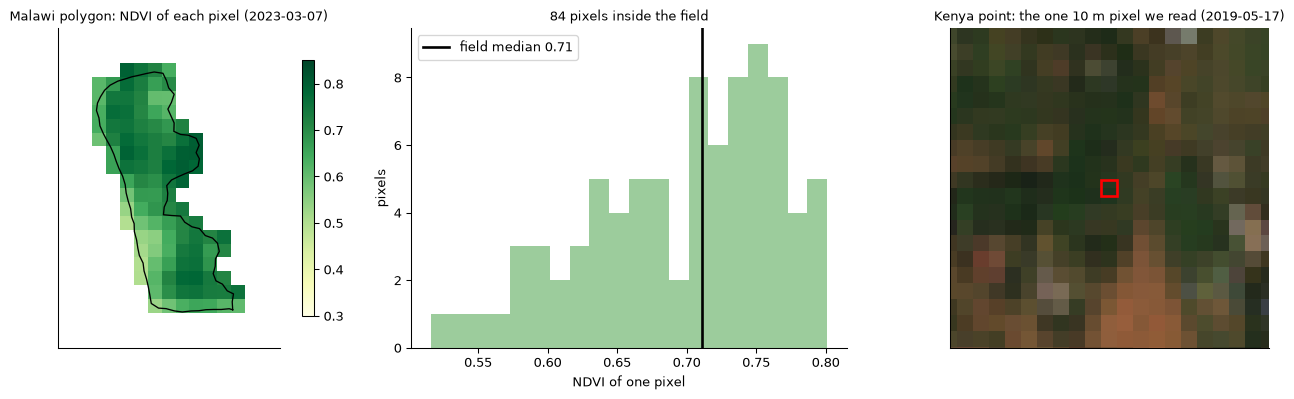

In [7]:
point_chip, point_record, point_series = load_field(POINT_ID)
ndvi_map = ndvi_of(greenest, chip)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
pixels = axes[0].imshow(np.where(chip.aoi, ndvi_map, np.nan), cmap="YlGn", vmin=0.3, vmax=0.85)
for columns, rows_ in rings:
    axes[0].plot(columns, rows_, color="black", lw=1)
axes[0].set(xlim=(cols_in.min() - 3, cols_in.max() + 3), ylim=(rows_in.max() + 3, rows_in.min() - 3), xticks=[],
            yticks=[], title=f"Malawi polygon: NDVI of each pixel ({greenest.date})")
fig.colorbar(pixels, ax=axes[0], shrink=0.8)
values = ndvi_map[field]
axes[1].hist(values[np.isfinite(values)], bins=20, color="#9ccc9c")
axes[1].axvline(np.nanmedian(values), color="black", lw=2, label=f"field median {np.nanmedian(values):.2f}")
axes[1].set(xlabel="NDVI of one pixel", ylabel="pixels", title=f"{int(field.sum())} pixels inside the field")
axes[1].legend()
point_green = max(point_chip.scenes, key=lambda s: np.nanmedian(ndvi_of(s, point_chip)[point_chip.aoi]))
axes[2].imshow(rgb(point_green, point_chip))
(point_col, point_row), = [(c[0], r[0]) for c, r in outline(point_chip, point_record)]
axes[2].add_patch(Rectangle((point_col - 0.5, point_row - 0.5), 1, 1, fill=False, edgecolor="red", lw=2))
axes[2].set(xlim=(point_col - 10, point_col + 10), ylim=(point_row + 10, point_row - 10), xticks=[], yticks=[],
            title=f"Kenya point: the one 10 m pixel we read ({point_green.date})")
plt.tight_layout()
plt.show()

### B. Cut a slice: one month as an image (CNN, MOSAIKS)

A CNN or MOSAIKS reads one month (or a few) **as a picture**: 10 bands × 64 × 64. It keeps neighbourhood and
texture, but it also sees the neighbours' fields, roads and trees around ours.

MOSAIKS in three pictures: take a small random 3 × 3 patch from some image as a **filter**; slide it over the
whole image (each output pixel says "how much does this spot look like the patch?"); average the result into
**one number**. With K different random patches you get K numbers per image. The cell shows one patch; the
project's real features (`scripts/features/mosaiks_features.py`) use 512 whitened patches and also the negative
response, so K = 1024 numbers per month, averaged once over the whole chip and once over the field pixels.

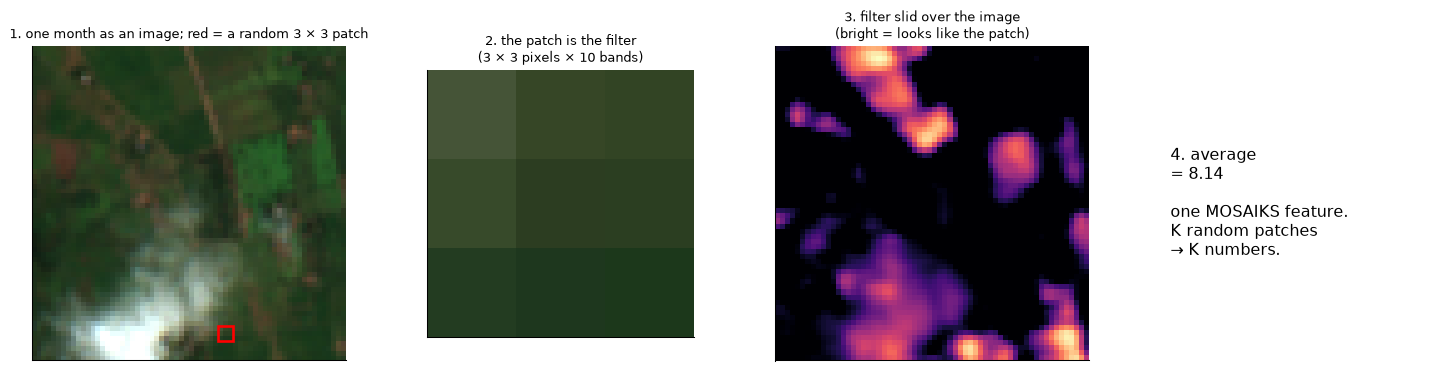

In [8]:
slice_ = np.nan_to_num(greenest.reflectance, nan=0.0)
mean, std = slice_.mean(axis=(1, 2), keepdims=True), slice_.std(axis=(1, 2), keepdims=True)
standard = (slice_ - mean) / std
rng = np.random.default_rng(7)
top, left = rng.integers(0, 61, size=2)
patch = standard[:, top:top + 3, left:left + 3]
response = F.relu(F.conv2d(torch.tensor(standard[None], dtype=torch.float32),
                           torch.tensor(patch[None], dtype=torch.float32)) - 1.0)[0, 0].numpy()

fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 0.55, 1, 0.55]})
axes[0].imshow(rgb(greenest, chip))
axes[0].add_patch(Rectangle((left - 0.5, top - 0.5), 3, 3, fill=False, edgecolor="red", lw=2))
axes[0].set_title("1. one month as an image; red = a random 3 × 3 patch")
patch_rgb = np.clip(np.stack([greenest.reflectance[chip.bands.index(b)][top:top + 3, left:left + 3]
                              for b in ("B04", "B03", "B02")], axis=-1) / 0.3, 0, 1)
axes[1].imshow(np.nan_to_num(patch_rgb, nan=1.0))
axes[1].set_title("2. the patch is the filter\n(3 × 3 pixels × 10 bands)")
axes[2].imshow(response, cmap="magma")
axes[2].set_title("3. filter slid over the image\n(bright = looks like the patch)")
axes[3].axis("off")
axes[3].text(0.0, 0.5, f"4. average\n= {response.mean():.2f}\n\none MOSAIKS feature.\nK random patches\n→ K numbers.",
             fontsize=12, va="center")
for ax in axes[:3]:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

### C. Pre-digested: AlphaEarth

AlphaEarth Foundations (Google DeepMind, 2025) is a model that **already read** many sensors (Sentinel-2,
Landsat, Sentinel-1 radar, elevation, climate and more) through a whole year, **and** each pixel's neighbourhood.
Google ran it once for the whole Earth and published the result: for every 10 m pixel and every year from 2017
to 2024, **64 numbers** (bands `A00` … `A63` in Earth Engine). Nobody fine-tunes it; you only read the numbers.

So for us AlphaEarth would look like **64 extra "bands" with one value per year**: we would read them at the
field pixels, take the median, and get 64 numbers per field-season. Easy to join, but there is no monthly time
series inside a season, and it needs Earth Engine access. It is not in our data yet.

The figure puts the three readings side by side on the same kind of cube.

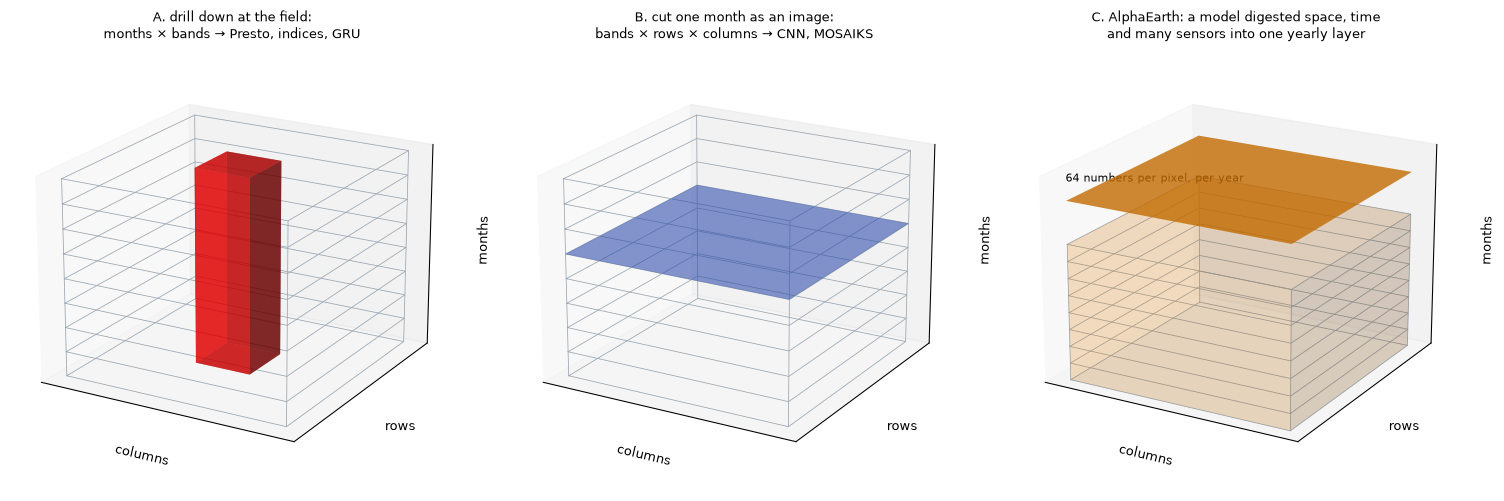

In [9]:
def draw_cube(ax, n_months=9, size=8):
    for z in range(n_months):
        ax.plot([0, size, size, 0, 0], [0, 0, size, size, 0], [z] * 5, color="#9aa7b4", lw=0.6)
    for x, y in [(0, 0), (size, 0), (size, size), (0, size)]:
        ax.plot([x, x], [y, y], [0, n_months - 1], color="#9aa7b4", lw=0.6)
    ax.set(xticks=[], yticks=[], zticks=[], xlabel="columns", ylabel="rows", zlabel="months")
    ax.view_init(elev=20, azim=-60)


fig = plt.figure(figsize=(16, 5.2))
ax = fig.add_subplot(1, 3, 1, projection="3d")
draw_cube(ax)
ax.bar3d(3, 3, 0, 2, 2, 8, color="red", alpha=0.6)
ax.set_title("A. drill down at the field:\nmonths × bands → Presto, indices, GRU")
ax = fig.add_subplot(1, 3, 2, projection="3d")
draw_cube(ax)
xx, yy = np.meshgrid(np.linspace(0, 8, 2), np.linspace(0, 8, 2))
ax.plot_surface(xx, yy, np.full(xx.shape, 5.0), color="royalblue", alpha=0.6)
ax.set_title("B. cut one month as an image:\nbands × rows × columns → CNN, MOSAIKS")
ax = fig.add_subplot(1, 3, 3, projection="3d")
draw_cube(ax)
ax.bar3d(0, 0, 0, 8, 8, 8, color="darkorange", alpha=0.12)
ax.plot_surface(xx, yy, np.full(xx.shape, 10.5), color="darkorange", alpha=0.8)
ax.text(0, 0, 11.6, "64 numbers per pixel, per year", fontsize=8)
ax.set_zlim(0, 12)
ax.set_title("C. AlphaEarth: a model digested space, time\nand many sensors into one yearly layer")
plt.tight_layout()
plt.show()

## 5. From 48 cubes to one table with one yield per row

Do step A for every pilot field and you get one small table per field. The label (yield) sits in the audit row
with the same `obs_id`. Below, every line is one field's NDVI season, coloured by its measured yield. This is the
relation the models must learn: *does a greener, longer season mean more maize?* In some cohorts you can almost
see it; in others (many zero yields in Zimbabwe 2024) you cannot.

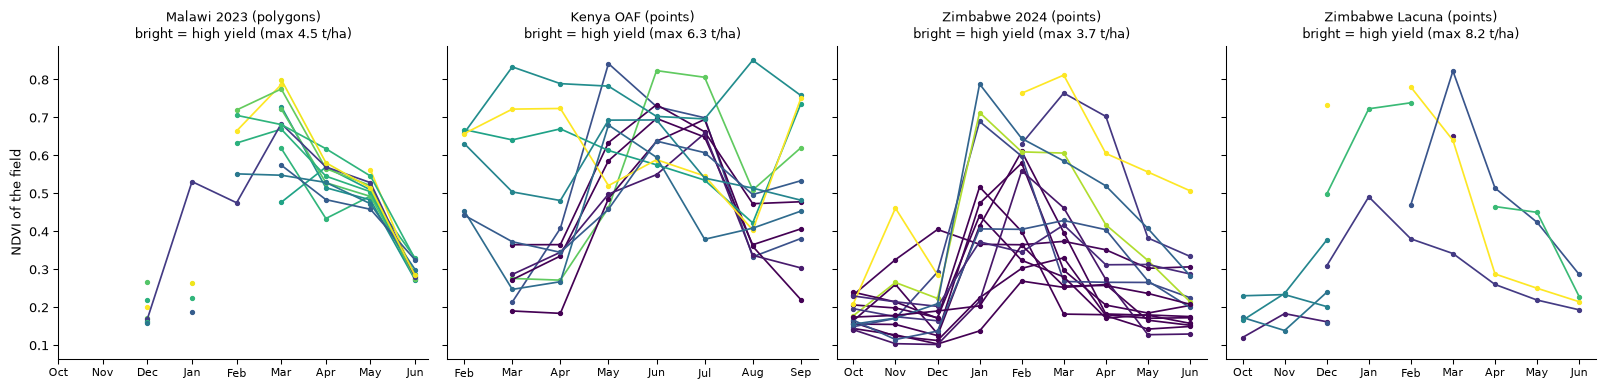

In [10]:
cohort_names = {"malawi_2023": "Malawi 2023 (polygons)", "kenya_oaf_2019_2020": "Kenya OAF (points)",
                "zimbabwe_2024": "Zimbabwe 2024 (points)", "zimbabwe_lacuna_2022_2023": "Zimbabwe Lacuna (points)"}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
colour_scale = plt.cm.viridis
for ax, (cohort, title) in zip(axes, cohort_names.items()):
    ids = pilot.index[pilot["cohort"] == cohort]
    top_yield = pilot.loc[ids, "yield_kg_ha"].max() or 1
    for obs_id in ids:
        _, _, s = load_field(obs_id)
        curve = (s.band("B08") - s.band("B04")) / (s.band("B08") + s.band("B04"))
        ax.plot(range(len(s.months)), curve, "o-", ms=3, lw=1.3,
                color=colour_scale(pilot.at[obs_id, "yield_kg_ha"] / top_yield))
    ax.set_xticks(range(len(s.months)), [date(2000, int(m[5:]), 1).strftime("%b") for m in s.months], fontsize=8)
    ax.set_title(f"{title}\nbright = high yield (max {top_yield / 1000:.1f} t/ha)")
axes[0].set_ylabel("NDVI of the field")
plt.tight_layout()
plt.show()

The last step is a join on `obs_id`: label row + features → one row per field. `scripts/build_database.py`
writes every part as its own table in `data/cropyield.duckdb` and joins them in the view `master`; see
`04_database.ipynb`.

## 6. Your questions, answered in one table

| Question | Answer |
|---|---|
| Do we download the whole satellite image? | No. A 640 m × 640 m window around each field, one clear scene per month of the season. About 2 MB per field instead of about 1 GB per full scene. |
| Do we have the raw pixels? | Yes. Every chip keeps all 64 × 64 pixels × 10 bands per month (section 3). |
| Do we put the pixels into a CNN? | Not for Presto. A CNN or MOSAIKS can read the chip as an image (reading B). |
| Is a "band" extracted from the image? | A band *is* one layer of the image: the brightness at one colour of light (sections 1–2). |
| How does Presto read the data? | Reading A: the field's 10 band values per month, a months × bands table, plus lat/lon. No neighbours. |
| Does AlphaEarth work like that? | No. It already read space, time and many sensors; it gives 64 finished numbers per pixel per year (reading C). |
| How do the label and the satellite data meet? | lat/lon (and the Malawi polygon) place the chip once; after that, `obs_id` joins everything. |